In [1]:
import pandas as pd
import numpy as np
import sqlite3

np.random.seed(42)

# 76 applicants - Week 2 jaisa pattern
domains = ['Web Development']*36 + ['Data Science']*18 + ['Graphic Design']*12 + ['Digital Marketing']*10
universities = ['Karachi University']*23 + ['NED University']*15 + ['IBA']*12 + ['SZABIST']*10 + ['Other']*16

np.random.shuffle(domains)
np.random.shuffle(universities)

applicants = pd.DataFrame({
    'applicant_id': range(1, 77),
    'name': [f'Applicant {i}' for i in range(1, 77)],
    'domain': domains,
    'university': universities,
    'application_date': pd.date_range('2026-08-01', periods=76).strftime('%Y-%m-%d'),
    'status': ['Selected']*24 + ['Rejected']*30 + ['Under Review']*22
})
np.random.shuffle(applicants['status'].values)

# 24 interns - sirf Selected wale
selected = applicants[applicants['status']=='Selected'].copy()
interns = pd.DataFrame({
    'intern_id': range(1, 25),
    'applicant_id': selected['applicant_id'].values,
    'domain': selected['domain'].values,
    'start_date': '2026-09-01',
    'completion_status': ['Completed']*19 + ['Dropped Out']*5
})
np.random.shuffle(interns['completion_status'].values)

# Hackathon scores - sirf Completed wale
completed = interns[interns['completion_status']=='Completed']
scores = pd.DataFrame({
    'intern_id': completed['intern_id'].values,
    'score': np.random.randint(60, 99, size=len(completed)),
    'domain': completed['domain'].values
})

# SQLite DB banao
conn = sqlite3.connect('nextgen.db')
applicants.to_sql('applicants', conn, if_exists='replace', index=False)
interns.to_sql('interns', conn, if_exists='replace', index=False)
scores.to_sql('hackathon_scores', conn, if_exists='replace', index=False)

print("Done!")
print(applicants.head())
print(interns.head())
print(scores.head())
print("Applicants:", len(applicants), "| Interns:", len(interns), "| Scores:", len(scores))
     

Done!
   applicant_id         name           domain          university  \
0             1  Applicant 1  Web Development                 IBA   
1             2  Applicant 2  Web Development               Other   
2             3  Applicant 3  Web Development      NED University   
3             4  Applicant 4  Web Development      NED University   
4             5  Applicant 5     Data Science  Karachi University   

  application_date    status  
0       2026-08-01  Selected  
1       2026-08-02  Selected  
2       2026-08-03  Rejected  
3       2026-08-04  Rejected  
4       2026-08-05  Selected  
   intern_id  applicant_id           domain  start_date completion_status
0          1             1  Web Development  2026-09-01         Completed
1          2             2  Web Development  2026-09-01         Completed
2          3             5     Data Science  2026-09-01         Completed
3          4             6     Data Science  2026-09-01         Completed
4          5           

In [3]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('nextgen.db')

print("APPLICANTS")
print(pd.read_sql("SELECT * FROM applicants LIMIT 5;", conn))
print("\nINTERNS")
print(pd.read_sql("SELECT * FROM interns LIMIT 5;", conn))
print("\nSCORES")
print(pd.read_sql("SELECT * FROM hackathon_scores LIMIT 5;", conn))

APPLICANTS
   applicant_id         name           domain          university  \
0             1  Applicant 1  Web Development                 IBA   
1             2  Applicant 2  Web Development               Other   
2             3  Applicant 3  Web Development      NED University   
3             4  Applicant 4  Web Development      NED University   
4             5  Applicant 5     Data Science  Karachi University   

  application_date    status  
0       2026-08-01  Selected  
1       2026-08-02  Selected  
2       2026-08-03  Rejected  
3       2026-08-04  Rejected  
4       2026-08-05  Selected  

INTERNS
   intern_id  applicant_id           domain  start_date completion_status
0          1             1  Web Development  2026-09-01         Completed
1          2             2  Web Development  2026-09-01         Completed
2          3             5     Data Science  2026-09-01         Completed
3          4             6     Data Science  2026-09-01         Completed
4        

In [5]:

# Query 1: Har domain me kitne interns ne program complete kiya?
q1 = """
-- Counts completed interns grouped by domain
SELECT domain, COUNT(*) AS completed_count
FROM interns
WHERE completion_status = 'Completed'
GROUP BY domain
ORDER BY completed_count DESC;
"""
print(pd.read_sql(q1, conn))

              domain  completed_count
0    Web Development                9
1       Data Science                6
2     Graphic Design                3
3  Digital Marketing                1


In [7]:
q2 = """
-- Calculates the average hackathon score for each domain
SELECT domain, ROUND(AVG(score), 2) AS avg_score
FROM hackathon_scores
GROUP BY domain
ORDER BY avg_score DESC;
"""
print(pd.read_sql(q2, conn))

              domain  avg_score
0  Digital Marketing      96.00
1    Web Development      81.33
2     Graphic Design      72.00
3       Data Science      68.33


In [9]:

q3 = """
-- Lists interns who scored 85 or above, as candidates for showcase/certificates
SELECT i.intern_id, i.domain, h.score
FROM interns i
JOIN hackathon_scores h ON i.intern_id = h.intern_id
WHERE h.score >= 85
ORDER BY h.score DESC;
"""
print(pd.read_sql(q3, conn))

   intern_id             domain  score
0          7  Digital Marketing     96
1         10    Web Development     94
2         19    Web Development     92
3          8    Web Development     91
4          2    Web Development     85


In [11]:
q4 = """
-- Compares total applicants vs completed interns per domain to find conversion rate
SELECT
    a.domain,
    COUNT(DISTINCT a.applicant_id) AS total_applicants,
    COUNT(DISTINCT i.intern_id) AS total_completed,
    ROUND(100.0 * COUNT(DISTINCT i.intern_id) / COUNT(DISTINCT a.applicant_id), 2) AS conversion_rate_pct
FROM applicants a
LEFT JOIN interns i
    ON a.applicant_id = i.applicant_id AND i.completion_status = 'Completed'
GROUP BY a.domain
ORDER BY conversion_rate_pct DESC;
"""
print(pd.read_sql(q4, conn))

              domain  total_applicants  total_completed  conversion_rate_pct
0       Data Science                18                6                33.33
1    Web Development                36                9                25.00
2     Graphic Design                12                3                25.00
3  Digital Marketing                10                1                10.00


In [13]:

q5 = """
-- Shows which universities send the most applicants and how many complete
SELECT
    a.university,
    COUNT(DISTINCT a.applicant_id) AS total_applicants,
    COUNT(DISTINCT i.intern_id) AS total_completed
FROM applicants a
LEFT JOIN interns i
    ON a.applicant_id = i.applicant_id AND i.completion_status = 'Completed'
GROUP BY a.university
ORDER BY total_applicants DESC;
"""
print(pd.read_sql(q5, conn))

           university  total_applicants  total_completed
0  Karachi University                23                6
1               Other                16                3
2      NED University                15                3
3                 IBA                12                4
4             SZABIST                10                3


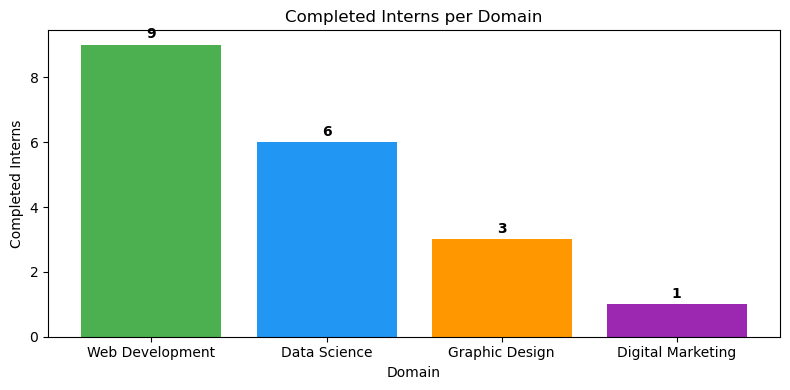

              domain  completed
0    Web Development          9
1       Data Science          6
2     Graphic Design          3
3  Digital Marketing          1


In [15]:
# Charts for Week 3 Dashboard
import matplotlib.pyplot as plt

# Chart 1: Completed interns per domain
q_chart1 = """
SELECT domain, COUNT(*) AS completed
FROM interns
WHERE completion_status = 'Completed'
GROUP BY domain
ORDER BY completed DESC;
"""
df1 = pd.read_sql(q_chart1, conn)

plt.figure(figsize=(8,4))
plt.bar(df1['domain'], df1['completed'], color=['#4CAF50','#2196F3','#FF9800','#9C27B0'])
plt.title('Completed Interns per Domain')
plt.xlabel('Domain')
plt.ylabel('Completed Interns')
for i, v in enumerate(df1['completed']):
    plt.text(i, v+0.2, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()
print(df1)

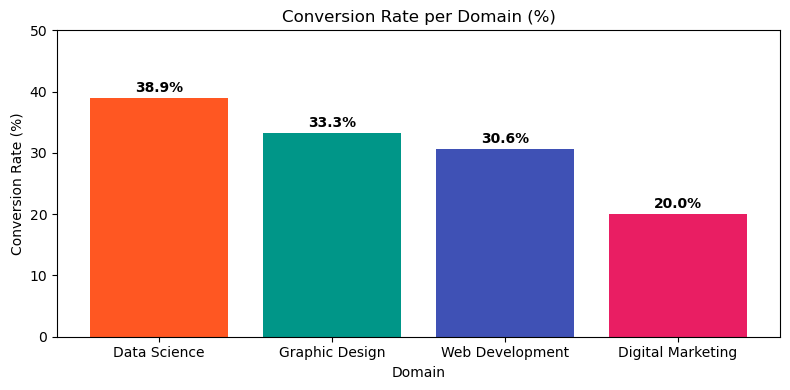

              domain  total_applicants  total_interns  conversion_rate
0       Data Science                18              7             38.9
1     Graphic Design                12              4             33.3
2    Web Development                36             11             30.6
3  Digital Marketing                10              2             20.0


In [17]:
# Chart 2: Conversion Rate per Domain (%)
import matplotlib.pyplot as plt

q_chart2 = """
SELECT a.domain,
       COUNT(a.applicant_id) AS total_applicants,
       COUNT(i.intern_id) AS total_interns,
       ROUND(COUNT(i.intern_id)*100.0/COUNT(a.applicant_id), 1) AS conversion_rate
FROM applicants a
LEFT JOIN interns i ON a.applicant_id = i.applicant_id
GROUP BY a.domain
ORDER BY conversion_rate DESC;
"""
df2 = pd.read_sql(q_chart2, conn)

plt.figure(figsize=(8,4))
plt.bar(df2['domain'], df2['conversion_rate'], color=['#FF5722','#009688','#3F51B5','#E91E63'])
plt.title('Conversion Rate per Domain (%)')
plt.xlabel('Domain')
plt.ylabel('Conversion Rate (%)')
plt.ylim(0, 50)
for i, v in enumerate(df2['conversion_rate']):
    plt.text(i, v+1, f"{v}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()
print(df2)
     

In [23]:
import pandas as pd
import random
from datetime import date, timedelta

# Week 3 work includes the files: dashboard.py, nextgen.db
# Create csv files applicants, interns, hackathin scores to be use in sql database

# Makes results reproducible
random.seed(42)


# TABLE 1: APPLICANTS


first_names = [
    "Mwelwa", "Thabo", "Lerato", "Aisha", "Daniel",
    "Naledi", "Sipho", "Amara", "James", "Zanele",
    "Chipo", "Michael", "Grace", "Kabelo", "Tendai",
    "Sarah", "Liam", "Nomsa", "David", "Faith"
]

last_names = [
    "Banda", "Nkosi", "Moyo", "Smith", "Dlamini",
    "Phiri", "Jones", "Khumalo", "Tembo", "Williams",
    "Zulu", "Ndlovu", "Molefe", "Brown", "Chanda"
]

domains = ["Data Science", "AI", "Software Development", "Cybersecurity"]

universities = [
    "University of Cape Town",
    "University of Pretoria",
    "University of Johannesburg",
    "University of Zambia",
    "Stellenbosch University",
    "University of the Witwatersrand",
    "University of Botswana"
]

applicants = []

for i in range(1, 101):
     # First 30 are selected, next 35 under review,
    # remaining 35 are rejected.
    if i <= 30:
        status = "Selected"
    elif i <= 65:
        status = "Under Review"
    else:
        status = "Rejected"

    application_date = date(2026, 3, 1) + timedelta(
        days=random.randint(0, 110)
    )

    applicants.append({
        "applicant_id": f"A{i:03d}",
        "name": random.choice(first_names) + " " + random.choice(last_names),
        "domain": random.choice(domains),
        "university": random.choice(universities),
        "application_date": application_date.isoformat(),
        "status": status
    })

applicants_df = pd.DataFrame(applicants)



# TABLE 2: INTERNS


interns = []

# All 30 selected applicants start the programme.
for i in range(1, 31):

    # 25 complete, 5 drop out.
    if i <= 25:
        completion_status = "Completed"
    else:
        completion_status = "Dropped Out"

    interns.append({
        "intern_id": f"I{i:03d}",
        "applicant_id": f"A{i:03d}",
        "domain": applicants_df.loc[i-1, "domain"],
        "start_date": (
            date(2026, 6, 1) + timedelta(days=random.randint(0, 10))
        ).isoformat(),
        "completion_status": completion_status
    })

interns_df = pd.DataFrame(interns)


# TABLE 3: HACKATHON SCORES


hackathon_scores = []

# 20 completed interns reach the hackathon.
for i in range(1, 21):

    hackathon_scores.append({
        "intern_id": f"I{i:03d}",
        "score": random.randint(45, 100),
        "domain": interns_df.loc[i-1, "domain"]
    })
scores_df = pd.DataFrame(hackathon_scores)



# EXPORT ALL THREE TABLES

applicants_df.to_csv("applicants.csv", index=False)
interns_df.to_csv("interns.csv", index=False)
scores_df.to_csv("hackathon_scores.csv", index=False)

print("All three CSV files have been created!")

print("\nApplicants:")
display(applicants_df.head())

print("\nInterns:")
display(interns_df.head())

print("\nHackathon Scores:")
display(scores_df.head())
     


All three CSV files have been created!

Applicants:


,applicant_id,name,domain,university,application_date,status
0,A001,Aisha Banda,Software Development,University of Pretoria,2026-05-21,Selected
1,A002,Daniel Ndlovu,Data Science,University of the Witwatersrand,2026-03-29,Selected
2,A003,Nomsa Nkosi,Cybersecurity,University of Cape Town,2026-06-03,Selected
3,A004,Lerato Smith,AI,Stellenbosch University,2026-03-04,Selected
4,A005,Mwelwa Tembo,AI,University of the Witwatersrand,2026-05-17,Selected



Interns:


,intern_id,applicant_id,domain,start_date,completion_status
0,I001,A001,Software Development,2026-06-02,Completed
1,I002,A002,Data Science,2026-06-05,Completed
2,I003,A003,Cybersecurity,2026-06-06,Completed
3,I004,A004,AI,2026-06-11,Completed
4,I005,A005,AI,2026-06-09,Completed



Hackathon Scores:


,intern_id,score,domain
0,I001,90,Software Development
1,I002,72,Data Science
2,I003,45,Cybersecurity
3,I004,78,AI
4,I005,96,AI
